# Type 2 Diabetes Risk Model: Pima Indians Diabetes Data

**Question:** How well do eight routinely measured variables identify diabetes, once impossible zero values are handled properly and the model is evaluated without leakage? Are the predicted risks well calibrated?

**Data:** *Pima Indians Diabetes Database* (National Institute of Diabetes and Digestive and Kidney Diseases; donated to UCI by V. Sigillito, 1990), obtained from OpenML (dataset 37, licence "Public"). 768 women of Pima Indian heritage aged 21 or older. The outcome is diabetes by WHO criteria (2-hour post-load plasma glucose ≥ 200 mg/dl at a survey examination, or found during routine care).

> Research and education only. This isn't a clinical screening tool.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")  # avoids a noisy CPU-count probe on Windows

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn import svm
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from diabetes_risk import (FEATURES, ZERO_MEANS_MISSING, bootstrap_ci, load_raw, make_model, repeated_cv,
                           screening_metrics, sha256, zeros_to_missing)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", "{:.3f}".format)
RAW = ROOT / "data" / "raw" / "openml_37_diabetes.arff"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

## 1. Data and the zero problem

In [2]:
assert sha256(RAW) == "4eddd5b2b64679e8888348e306520a393d6a28e1ddc9643cfb76fc5d912d6d40"
raw = load_raw(RAW)
y = raw["diabetes"].values
print(f"{len(raw)} women; diabetes: {y.sum()} ({y.mean():.1%})")
pd.DataFrame({"zeros": (raw[ZERO_MEANS_MISSING] == 0).sum(),
              "% of rows": (raw[ZERO_MEANS_MISSING] == 0).mean() * 100})

768 women; diabetes: 268 (34.9%)


,zeros,% of rows
Glucose,5,0.651
BloodPressure,35,4.557
SkinThickness,227,29.557
Insulin,374,48.698
BMI,11,1.432


A glucose, blood pressure, skinfold thickness, insulin or BMI of **0 is physiologically impossible**: it means the value wasn't recorded. Nearly half of insulin values and 30% of skinfold values are missing. Treating zeros as real measurements (as the earlier version did) distorts the scaling and the model. Here they're converted to missing, then median-imputed **inside each training fold**, with an indicator column for each variable that was missing in the training data.

In [3]:
df = zeros_to_missing(raw)
X = df[FEATURES]
df.groupby("diabetes")[FEATURES].median().T.rename(columns={0: "no diabetes (median)", 1: "diabetes (median)"})

diabetes,no diabetes (median),diabetes (median)
Pregnancies,2.000,4.000
Glucose,107.000,140.000
BloodPressure,70.000,74.500
SkinThickness,27.000,32.000
Insulin,102.500,169.500
BMI,30.100,34.300
DiabetesPedigree,0.336,0.449
Age,27.000,36.000


## 2. Reproducing the original evaluation

The original notebook fit `StandardScaler` on the **whole dataset** before a single 80/20 split, kept the zeros, trained a linear SVM and reported only accuracy. That procedure is reproduced here for reference.

In [4]:
scaled = StandardScaler().fit_transform(raw[FEATURES])
Xtr, Xte, ytr, yte = train_test_split(scaled, y, test_size=0.2, stratify=y, random_state=2)
clf = svm.SVC(kernel="linear").fit(Xtr, ytr)
print(f"Original procedure: train accuracy {accuracy_score(ytr, clf.predict(Xtr)):.3f}, test accuracy {accuracy_score(yte, clf.predict(Xte)):.3f}")
print(f"Accuracy of always predicting 'no diabetes': {1 - y.mean():.3f}")

Original procedure: train accuracy 0.787, test accuracy 0.773
Accuracy of always predicting 'no diabetes': 0.651


The single split matches the earlier README (77.3% test accuracy). Accuracy alone is a weak yardstick here: predicting "no diabetes" for everyone already scores 65.1%. A single split also says nothing about variability, and the model gives no risk probabilities.

## 3. Models and validation

* **Primary model:** logistic regression (interpretable, gives probabilities).
* **Comparisons:** a linear SVM (the original model family, with Platt-scaled probabilities) and histogram gradient boosting.
* **Validation:** stratified 5-fold CV repeated 20 times. Imputation and scaling are fit inside each fold.
* **Two operating points:** a fixed 0.5 threshold, and a threshold chosen inside each training fold (inner 5-fold CV) to reach **85% sensitivity**, suitable for a first-stage screen followed by confirmatory testing.

In [5]:
models = {
    "Logistic regression (primary)": lambda: make_model(LogisticRegression(max_iter=2000)),
    "Linear SVM (original model family)": lambda: make_model(svm.SVC(kernel="linear", probability=True, random_state=0)),
    "Gradient boosting": lambda: make_model(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                                          max_iter=200, random_state=0)),
}
cv_results = {name: repeated_cv(f, X, y, n_repeats=20, target_sensitivity=0.85) for name, f in models.items()}

rows = {}
for name, reps in cv_results.items():
    _, lo, hi = bootstrap_ci(roc_auc_score, y, reps[0]["proba"])
    rows[name] = {
        "ROC-AUC (mean of 20 repeats)": np.mean([roc_auc_score(y, r["proba"]) for r in reps]),
        "ROC-AUC 95% CI (repeat 1)": f"{lo:.3f} to {hi:.3f}",
        "PR-AUC": np.mean([average_precision_score(y, r["proba"]) for r in reps]),
        "Brier score": np.mean([brier_score_loss(y, r["proba"]) for r in reps]),
        "accuracy @0.5": np.mean([((r["proba"] >= 0.5) == y).mean() for r in reps]),
    }
print(f"Reference Brier score for always predicting the prevalence: {y.mean() * (1 - y.mean()):.3f}; PR-AUC baseline = prevalence {y.mean():.3f}")
pd.DataFrame(rows).T

Reference Brier score for always predicting the prevalence: 0.227; PR-AUC baseline = prevalence 0.349


,ROC-AUC (mean of 20 repeats),ROC-AUC 95% CI (repeat 1),PR-AUC,Brier score,accuracy @0.5
Logistic regression (primary),0.832,0.807 to 0.864,0.708,0.158,0.771
Linear SVM (original model family),0.835,0.807 to 0.865,0.713,0.156,0.772
Gradient boosting,0.826,0.793 to 0.853,0.690,0.162,0.759


In [6]:
rows = []
for name, reps in cv_results.items():
    for label, key in [("threshold 0.5", "flag_05"), ("threshold for 85% sensitivity (chosen in training folds)", "flag_target")]:
        rows.append({"model": name, "operating point": label,
                     **pd.DataFrame([screening_metrics(y, r[key]) for r in reps]).mean().to_dict()})
pd.DataFrame(rows).set_index(["model", "operating point"])

sensitivity  \
model                              operating point                                                   
Logistic regression (primary)      threshold 0.5                                             0.572   
                                   threshold for 85% sensitivity (chosen in traini...        0.853   
Linear SVM (original model family) threshold 0.5                                             0.566   
                                   threshold for 85% sensitivity (chosen in traini...        0.851   
Gradient boosting                  threshold 0.5                                             0.609   
                                   threshold for 85% sensitivity (chosen in traini...        0.858   

                                                                                       specificity  \
model                              operating point                                                   
Logistic regression (primary)      threshold 0.5                                             0.878   
                                   threshold for 85% sensitivity (chosen in traini...        0.626   
Linear SVM (original model family) threshold 0.5                                             0.883   
                                   threshold for 85% sensitivity (chosen in traini...        0.633   
Gradient boosting                  threshold 0.5                                             0.840   
                                   threshold for 85% sensitivity (chosen in traini...        0.629   

                                                                                        PPV  \
model                              operating point                                            
Logistic regression (primary)      threshold 0.5                                      0.716   
                                   threshold for 85% sensitivity (chosen in traini... 0.550   
Linear SVM (original model family) threshold 0.5                                      0.721   
                                   threshold for 85% sensitivity (chosen in traini... 0.555   
Gradient boosting                  threshold 0.5                                      0.671   
                                   threshold for 85% sensitivity (chosen in traini... 0.553   

                                                                                        NPV  
model                              operating point                                           
Logistic regression (primary)      threshold 0.5                                      0.793  
                                   threshold for 85% sensitivity (chosen in traini... 0.888  
Linear SVM (original model family) threshold 0.5                                      0.791  
                                   threshold for 85% sensitivity (chosen in traini... 0.888  
Gradient boosting                  threshold 0.5                                      0.800  
                                   threshold for 85% sensitivity (chosen in traini... 0.892

## 4. Calibration

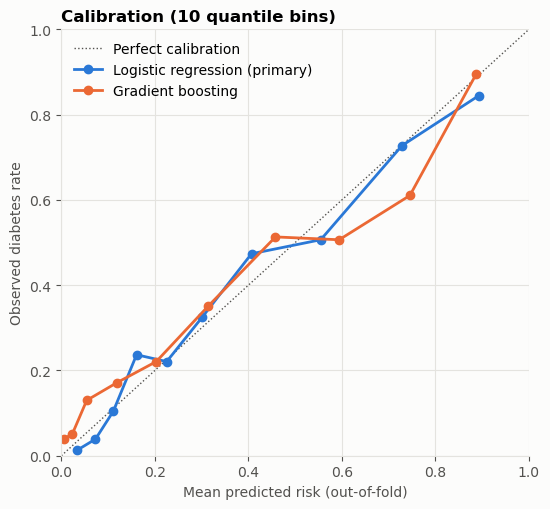

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=INK2, linestyle=":", linewidth=1, label="Perfect calibration")
for name, color in [("Logistic regression (primary)", BLUE), ("Gradient boosting", ORANGE)]:
    frac, mean_pred = calibration_curve(y, cv_results[name][0]["proba"], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, color=color, marker="o", markersize=6, label=name)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted risk (out-of-fold)")
ax.set_ylabel("Observed diabetes rate")
ax.set_title("Calibration (10 quantile bins)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Which variables matter? Adjusted odds ratios

An unpenalized logistic regression on the six variables with little missingness (insulin and skinfold thickness are excluded because 49% and 30% of values are missing), using complete cases. Odds ratios are **per 1 standard deviation** of each variable.

In [8]:
cols = ["Pregnancies", "Glucose", "BloodPressure", "BMI", "DiabetesPedigree", "Age"]
cc = df.dropna(subset=cols)
Z = (cc[cols] - cc[cols].mean()) / cc[cols].std()
fit = sm.Logit(cc["diabetes"], sm.add_constant(Z)).fit(disp=False)
odds = pd.DataFrame({"odds ratio per SD": np.exp(fit.params), "95% CI low": np.exp(fit.conf_int()[0]),
                     "95% CI high": np.exp(fit.conf_int()[1]), "p-value": fit.pvalues, "1 SD =": cc[cols].std()}).drop("const")
print(f"Complete cases: {len(cc)} of {len(df)}")
odds.sort_values("odds ratio per SD", ascending=False)

Complete cases: 724 of 768


,odds ratio per SD,95% CI low,95% CI high,p-value,1 SD =
Glucose,2.951,2.375,3.667,0.000,30.750
BMI,1.871,1.513,2.314,0.000,6.889
Pregnancies,1.486,1.193,1.853,0.000,3.363
DiabetesPedigree,1.376,1.127,1.680,0.002,0.332
Age,1.221,0.973,1.531,0.085,11.765
BloodPressure,0.895,0.727,1.104,0.301,12.380


In [9]:
small = ["Glucose", "BMI", "Age", "DiabetesPedigree"]
reps = repeated_cv(lambda: make_model(LogisticRegression(max_iter=2000)), df[small], y, n_repeats=20)
print(f"4-variable model (glucose, BMI, age, pedigree): ROC-AUC {np.mean([roc_auc_score(y, r['proba']) for r in reps]):.3f}")

4-variable model (glucose, BMI, age, pedigree): ROC-AUC 0.827


## 6. Findings

1. **With missing values handled and leakage removed, discrimination is moderate and model choice barely matters.** Logistic regression reached a mean cross-validated ROC-AUC of **0.832** (95% CI 0.807–0.864); the linear SVM reached 0.835 and gradient boosting 0.826. Brier score was 0.158, against 0.227 for predicting the prevalence for everyone. Nothing here justifies a more complex model.
2. **The original 77% accuracy holds up but hides poor sensitivity.** Cross-validated accuracy at 0.5 is 0.771, close to the earlier single-split 0.773, but at that threshold the model finds only **57% of women with diabetes** (specificity 0.878).
3. **For screening, a sensitivity-targeted threshold works as intended.** A threshold chosen inside training folds for 85% sensitivity achieved **0.853** on held-out women, with specificity 0.626, PPV 0.550 and NPV 0.888.
4. **Glucose dominates.** Adjusted odds ratios per SD (n = 724 complete cases): glucose 2.95 (2.37–3.67), BMI 1.87 (1.51–2.31), pregnancies 1.49 (1.19–1.85), diabetes pedigree 1.38 (1.13–1.68). Age (1.22, CI includes 1) and diastolic blood pressure (0.90) weren't independently associated. A four-variable model (glucose, BMI, age, pedigree) reached ROC-AUC 0.827, almost the full model.
5. **Calibration is acceptable.** Predicted risks broadly track observed rates for both logistic regression and gradient boosting, with some deviation in the middle of the range.

## 7. Limitations

* **One specific population** (Pima Indian women aged 21 or older, collected decades ago), so results don't transfer to other groups without external validation.
* **The outcome includes glucose tolerance test results**, and the `Glucose` feature is the 2-hour OGTT value, so the strongest predictor is close to the diagnostic test itself. This is better described as a diagnostic-classification exercise than a prediction of future diabetes.
* **Heavy missingness** in insulin (49%) and skinfold thickness (30%). Median imputation with indicators is simple; multiple imputation would be more rigorous.
* **Confidence intervals** for discrimination use one CV repeat's out-of-fold predictions; the means are over all 20 repeats.